In [1]:
%load_ext autoreload
%autoreload 2

from pathlib import Path
from collections import OrderedDict
from datasets import load_dataset
from torch.utils.data import DataLoader
from scipy.sparse import csr_matrix
from sklearn.metrics import classification_report
import torch.nn as nn

import experiment
import clslib
import analysis
import mmlp

In [2]:
dataset = load_dataset("stanfordnlp/sst2")
# temp_train_df = dataset["train"].to_pandas()
# temp_val_df = dataset["validation"].to_pandas()
# dataset_df = pd.concat([temp_train_df, temp_val_df], ignore_index=True).drop(columns=['idx'])
# train_df, val_df, test_df = np.split(dataset_df, [int(0.8 * len(dataset_df)), int(0.9 * len(dataset_df))])

# train_dataset = Dataset.from_pandas(train_df)
# val_dataset = Dataset.from_pandas(val_df)
# test_dataset = Dataset.from_pandas(test_df)
train_dataset = dataset["train"]
test_dataset = dataset["validation"]

In [3]:
vocab_size = 1000
min_frequency = 2
my_seeds = [0]
num_folds = 5
my_cross_validation_sets = []
results_folder = Path("./results")
results_folder.mkdir(exist_ok=True)

for seed in my_seeds:
    my_cross_validation_sets.append(
        experiment.cross_validation_split(
            # we pair the texts with their labels
            pairs=list(zip(train_dataset["sentence"], train_dataset["label"])), 
            k=num_folds,
            seed=seed
        )
    )

bpe_tokenizer = experiment.train_bpe_tokenizer(train_dataset["sentence"], vocab_size, min_frequency)
# tokenizer.save(f"{results_folder}/BPE_tokenizer_vs_{vocab_size}_mf_{min_frequency}.json")

bow_encoder = clslib.BagOfWords(bpe_tokenizer.get_vocab(), bpe_tokenizer)

my_classifiers = OrderedDict()

In [4]:
hidden_dim=128
hidden_dim_2=128
dropout=0.1
batch_size=64
learning_rate=1e-3
weight_decay=1e-4
num_epochs=10
device='cpu'

my_classifiers['modMLP_bow-enc'] = []

for run, seed in enumerate(my_seeds):    
    run_folder = f"{results_folder}/modMLP_bow-enc/seed-{seed}"
    my_classifiers['modMLP_bow-enc'].append(
        experiment.cross_validation_experiment(
            data_splits=my_cross_validation_sets[run],
            encoder=bow_encoder,
            model_option='mmlp',
            save_to=run_folder,
            mmlp_args={
                'hidden_dim': hidden_dim,
                'hidden_dim_2': hidden_dim_2,
                'dropout': dropout, 
                'batch_size': batch_size, 
                'learning_rate': learning_rate, 
                'weight_decay': weight_decay, 
                'num_epochs': num_epochs,
            }
        )
    )

  0%|          | 0/5 [00:00<?, ?it/s]

Transforming documents...
Document transformation done! Time taken: 26.438 seconds
Dataloader done! Time taken: 0.441 seconds
Training...


  0%|          | 0/10 [00:00<?, ?it/s]

c:\Users\PCUser\Desktop\UvA\NLP\NLP-Assignment-1\mmlp.py:75: UserWarning: Sparse invariant checks are implicitly disabled. Memory errors (e.g. SEGFAULT) will occur when operating on a sparse tensor which violates the invariants, but checks incur performance overhead. To silence this warning, explicitly opt in or out. See `torch.sparse.check_sparse_tensor_invariants.__doc__` for guidance.  (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\aten\src\ATen\Context.cpp:855.)
  return torch.sparse_coo_tensor(indices, values, size=x.shape).coalesce()


Epoch 01 | train loss: 0.4849 | train acc: 0.7594 | val loss: 0.3761 | val acc: 0.8322
Epoch 02 | train loss: 0.3105 | train acc: 0.8690 | val loss: 0.3043 | val acc: 0.8746
Epoch 03 | train loss: 0.2160 | train acc: 0.9154 | val loss: 0.2683 | val acc: 0.8929
Epoch 04 | train loss: 0.1614 | train acc: 0.9385 | val loss: 0.2663 | val acc: 0.9004
Epoch 05 | train loss: 0.1255 | train acc: 0.9517 | val loss: 0.2758 | val acc: 0.9071
Epoch 06 | train loss: 0.1022 | train acc: 0.9625 | val loss: 0.2986 | val acc: 0.9068
Epoch 07 | train loss: 0.0838 | train acc: 0.9694 | val loss: 0.3090 | val acc: 0.9092
Epoch 08 | train loss: 0.0778 | train acc: 0.9720 | val loss: 0.3066 | val acc: 0.9108
Epoch 09 | train loss: 0.0642 | train acc: 0.9760 | val loss: 0.3325 | val acc: 0.9114
Epoch 10 | train loss: 0.0604 | train acc: 0.9777 | val loss: 0.3369 | val acc: 0.9146
Training done! Time taken: 105.741 seconds
Transforming documents...
Document transformation done! Time taken: 24.834 seconds
Data

  0%|          | 0/10 [00:00<?, ?it/s]

... (3 outputs left out)

  0%|          | 0/10 [00:00<?, ?it/s]

Epoch 01 | train loss: 0.4876 | train acc: 0.7591 | val loss: 0.3865 | val acc: 0.8269
Epoch 02 | train loss: 0.3146 | train acc: 0.8664 | val loss: 0.3090 | val acc: 0.8704
Epoch 03 | train loss: 0.2193 | train acc: 0.9131 | val loss: 0.2787 | val acc: 0.8910
Epoch 04 | train loss: 0.1605 | train acc: 0.9378 | val loss: 0.2742 | val acc: 0.8970
Epoch 05 | train loss: 0.1256 | train acc: 0.9530 | val loss: 0.2911 | val acc: 0.9029
Epoch 06 | train loss: 0.1016 | train acc: 0.9618 | val loss: 0.2943 | val acc: 0.9091
Epoch 07 | train loss: 0.0859 | train acc: 0.9674 | val loss: 0.3274 | val acc: 0.9071
Epoch 08 | train loss: 0.0732 | train acc: 0.9727 | val loss: 0.3287 | val acc: 0.9060
Epoch 09 | train loss: 0.0645 | train acc: 0.9758 | val loss: 0.3463 | val acc: 0.9085
Epoch 10 | train loss: 0.0589 | train acc: 0.9785 | val loss: 0.3704 | val acc: 0.9122
Training done! Time taken: 90.865 seconds
Transforming documents...
Document transformation done! Time taken: 24.880 seconds
Datal

  0%|          | 0/10 [00:00<?, ?it/s]

Epoch 01 | train loss: 0.4840 | train acc: 0.7600 | val loss: 0.3873 | val acc: 0.8302
Epoch 02 | train loss: 0.3098 | train acc: 0.8677 | val loss: 0.3087 | val acc: 0.8717
Epoch 03 | train loss: 0.2155 | train acc: 0.9143 | val loss: 0.2800 | val acc: 0.8926
Epoch 04 | train loss: 0.1620 | train acc: 0.9368 | val loss: 0.2827 | val acc: 0.8998
Epoch 05 | train loss: 0.1273 | train acc: 0.9510 | val loss: 0.2852 | val acc: 0.9029
Epoch 06 | train loss: 0.1035 | train acc: 0.9615 | val loss: 0.2983 | val acc: 0.9062
Epoch 07 | train loss: 0.0854 | train acc: 0.9686 | val loss: 0.3137 | val acc: 0.9063
Epoch 08 | train loss: 0.0749 | train acc: 0.9722 | val loss: 0.3366 | val acc: 0.9073
Epoch 09 | train loss: 0.0664 | train acc: 0.9755 | val loss: 0.3557 | val acc: 0.9105
Epoch 10 | train loss: 0.0582 | train acc: 0.9788 | val loss: 0.3730 | val acc: 0.9107
Training done! Time taken: 95.242 seconds


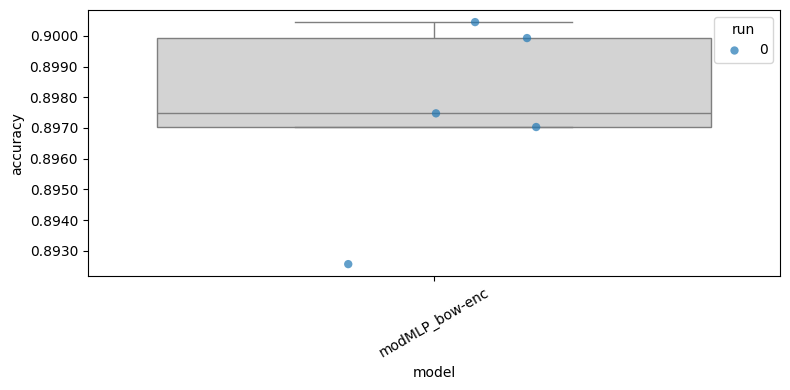

In [5]:
analysis.plot_box_and_points(analysis.make_data_frame(my_classifiers))

In [6]:
testing_sentences = test_dataset["sentence"]
testing_vectors = [bow_encoder(text) for text in testing_sentences]
testing_labels = test_dataset["label"]
X_test_sparse = csr_matrix(testing_vectors)
test_dataset_sparse = mmlp.SparseDataset(X_test_sparse, testing_labels)

test_loader = DataLoader(
        test_dataset_sparse,
        batch_size=batch_size,
        shuffle=False,
        collate_fn=mmlp.sparse_collate
    )

criterion = nn.BCEWithLogitsLoss()

for run, seed in enumerate(my_seeds):
    for fold in range(num_folds):    
        model_folder = f"{results_folder}/modMLP_bow-enc/seed-{seed}/fold-{fold}/model"
        model = mmlp.load(model_folder)

        mmlp.evaluate(model, test_loader, criterion, device)
        test_metrics, preds = mmlp.evaluate(model, test_loader, criterion, device)
        print(test_metrics)
        print(classification_report(testing_labels, preds))

{'loss': 0.760312240058129, 'accuracy': 0.7511467889908257}
              precision    recall  f1-score   support

           0       0.76      0.73      0.74       428
           1       0.75      0.77      0.76       444

    accuracy                           0.75       872
   macro avg       0.75      0.75      0.75       872
weighted avg       0.75      0.75      0.75       872

{'loss': 0.7440158402154206, 'accuracy': 0.7591743119266054}
              precision    recall  f1-score   support

           0       0.76      0.74      0.75       428
           1       0.76      0.78      0.77       444

    accuracy                           0.76       872
   macro avg       0.76      0.76      0.76       872
weighted avg       0.76      0.76      0.76       872

{'loss': 0.7195656392552437, 'accuracy': 0.7763761467889908}
              precision    recall  f1-score   support

           0       0.77      0.77      0.77       428
           1       0.78      0.78      0.78       444



In [7]:
# save results
Path("metrics").mkdir(exist_ok=True)

df = analysis.make_data_frame(my_classifiers)
df["seed"] = df["run"].map(dict(enumerate(my_seeds)))

df.to_csv(f"metrics/{next(iter(my_classifiers))}.csv", index=False)